# Goal
The goal is to use a simple model to classify x-ray images in Keras, the notebook how to use the ```flow_from_dataframe``` to deal with messier datasets

In [1]:
import numpy as np
import polars as pl
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt

In [2]:
import tensorflow as tf
from tensorflow.keras import mixed_precision

physical_gpus = tf.config.list_physical_devices('GPU')
if physical_gpus:
    for gpu in physical_gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    mixed_precision.set_global_policy('mixed_float16')
    TRAIN_BATCH_SIZE = 64
    EVAL_BATCH_SIZE = 128
    print(f'Using GPU: {physical_gpus[0].name} | mixed precision enabled')
else:
    TRAIN_BATCH_SIZE = 32
    EVAL_BATCH_SIZE = 64
    print('No GPU detected; running on CPU')

Using GPU: /physical_device:GPU:0 | mixed precision enabled


In [3]:
import numpy as np
import polars as pl
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt

In [4]:
# Load NIH Chest X-rays dataset with Polars LazyFrame
dataset_root = '/Volumes/DFM/DATASETS/NIH Chest X-rays'
csv_path = os.path.join(dataset_root, 'Data_Entry_2017.csv')
images_pattern = os.path.join(dataset_root, 'images*', '*', '*.png')

# Create lazy dataframe and map image paths
all_image_paths = {os.path.basename(x): x for x in glob(images_pattern)}
print(f'Scans found: {len(all_image_paths)}')

# Load CSV with Polars (lazy)
all_xray_df = pl.scan_csv(csv_path)

# Add path column and transform age
all_xray_df = (
    all_xray_df
    .with_columns([
        pl.col('Image Index').map_elements(lambda x: all_image_paths.get(x, None), return_dtype=pl.Utf8).alias('path'),
        pl.col('Patient Age').map_elements(lambda x: int(x[:-1]) if isinstance(x, str) else x, return_dtype=pl.Int32).alias('Patient Age')
    ])
)

print(f'Total Headers: {all_xray_df.select(pl.len()).collect().item()}')
print(all_xray_df.head(3).collect())

Scans found: 112120
Total Headers: 112120
shape: (3, 13)
┌─────────────┬─────────────┬────────────┬────────────┬───┬────────────┬───────┬──────┬────────────┐
│ Image Index ┆ Finding     ┆ Follow-up  ┆ Patient ID ┆ … ┆ OriginalIm ┆ y]    ┆      ┆ path       │
│ ---         ┆ Labels      ┆ #          ┆ ---        ┆   ┆ agePixelSp ┆ ---   ┆ ---  ┆ ---        │
│ str         ┆ ---         ┆ ---        ┆ i64        ┆   ┆ acing[x    ┆ f64   ┆ str  ┆ str        │
│             ┆ str         ┆ i64        ┆            ┆   ┆ ---        ┆       ┆      ┆            │
│             ┆             ┆            ┆            ┆   ┆ f64        ┆       ┆      ┆            │
╞═════════════╪═════════════╪════════════╪════════════╪═══╪════════════╪═══════╪══════╪════════════╡
│ 00000001_00 ┆ Cardiomegal ┆ 0          ┆ 1          ┆ … ┆ 0.143      ┆ 0.143 ┆ null ┆ /Volumes/D │
│ 0.png       ┆ y           ┆            ┆            ┆   ┆            ┆       ┆      ┆ FM/DATASET │
│             ┆             ┆     

# Preprocessing Labels
Here we take the labels and make them into a more clear format. The primary step is to see the distribution of findings and then to convert them to simple binary labels

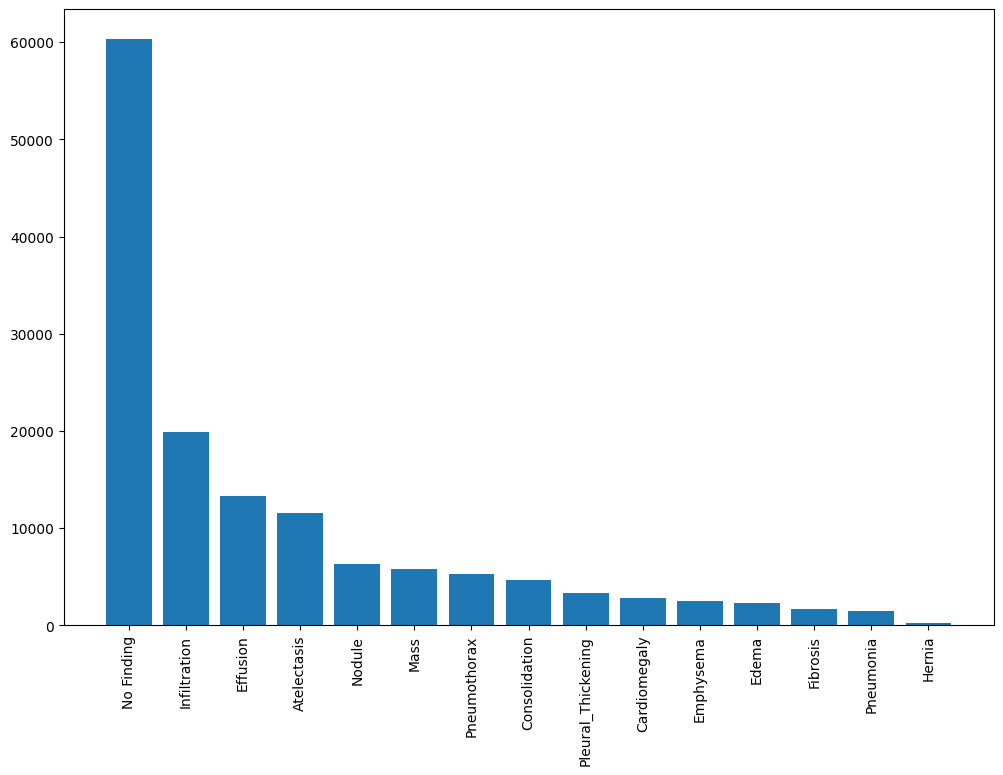

In [5]:
# Collect and analyze label distribution
xray_collected = all_xray_df.collect()
label_counts = (
    xray_collected
    .select('Finding Labels')
    .with_columns(
        pl.col('Finding Labels').str.split('|').alias('labels_list')
    )
    .explode('labels_list')
    .filter(pl.col('labels_list') != '')
    .group_by('labels_list')
    .len()
    .sort('len', descending=True)
    .head(15)
)

fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))
labels = label_counts['labels_list'].to_list()
counts = label_counts['len'].to_list()
ax1.bar(np.arange(len(counts)) + 0.5, counts)
ax1.set_xticks(np.arange(len(counts)) + 0.5)
_ = ax1.set_xticklabels(labels, rotation=90)

In [6]:
# Clean up Finding Labels and create binary columns for each diagnosis
xray_collected = (
    xray_collected
    .with_columns(
        pl.col('Finding Labels').str.replace_all('No Finding', '').alias('Finding Labels')
    )
)

# Extract unique labels from all records
from itertools import chain
all_labels_list = xray_collected['Finding Labels'].to_list()
all_labels_raw = list(chain(*[x.split('|') for x in all_labels_list]))
all_labels = sorted([x for x in set(all_labels_raw) if len(x) > 0])
print(f'All Labels ({len(all_labels)}): {all_labels}')

# Create binary columns for each label using native Polars
for c_label in all_labels:
    xray_collected = xray_collected.with_columns(
        pl.when(pl.col('Finding Labels').str.contains(c_label))
        .then(pl.lit(1.0))
        .otherwise(pl.lit(0.0))
        .cast(pl.Float32)
        .alias(c_label)
    )

print(xray_collected.head(3))

All Labels (14): ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
shape: (3, 27)
┌────────────┬────────────┬───────────┬───────────┬───┬────────┬───────────┬───────────┬───────────┐
│ Image      ┆ Finding    ┆ Follow-up ┆ Patient   ┆ … ┆ Nodule ┆ Pleural_T ┆ Pneumonia ┆ Pneumotho │
│ Index      ┆ Labels     ┆ #         ┆ ID        ┆   ┆ ---    ┆ hickening ┆ ---       ┆ rax       │
│ ---        ┆ ---        ┆ ---       ┆ ---       ┆   ┆ f32    ┆ ---       ┆ f32       ┆ ---       │
│ str        ┆ str        ┆ i64       ┆ i64       ┆   ┆        ┆ f32       ┆           ┆ f32       │
╞════════════╪════════════╪═══════════╪═══════════╪═══╪════════╪═══════════╪═══════════╪═══════════╡
│ 00000001_0 ┆ Cardiomega ┆ 0         ┆ 1         ┆ … ┆ 0.0    ┆ 0.0       ┆ 0.0       ┆ 0.0       │
│ 00.png     ┆ ly         ┆           ┆           ┆   ┆        ┆       

### Clean categories
Since we have too many categories, we can prune a few out by taking the ones with only a few examples

In [7]:
# Keep at least 1000 cases per label
MIN_CASES = 1000
label_sums = {label: xray_collected[label].sum() for label in all_labels}
all_labels = [c_label for c_label in all_labels if label_sums[c_label] > MIN_CASES]
print(f'Clean Labels ({len(all_labels)})')
for c_label in all_labels:
    print(f'  {c_label}: {int(label_sums[c_label])}')

Clean Labels (13)
  Atelectasis: 11559
  Cardiomegaly: 2776
  Consolidation: 4667
  Edema: 2303
  Effusion: 13317
  Emphysema: 2516
  Fibrosis: 1686
  Infiltration: 19894
  Mass: 5782
  Nodule: 6331
  Pleural_Thickening: 3385
  Pneumonia: 1431
  Pneumothorax: 5302


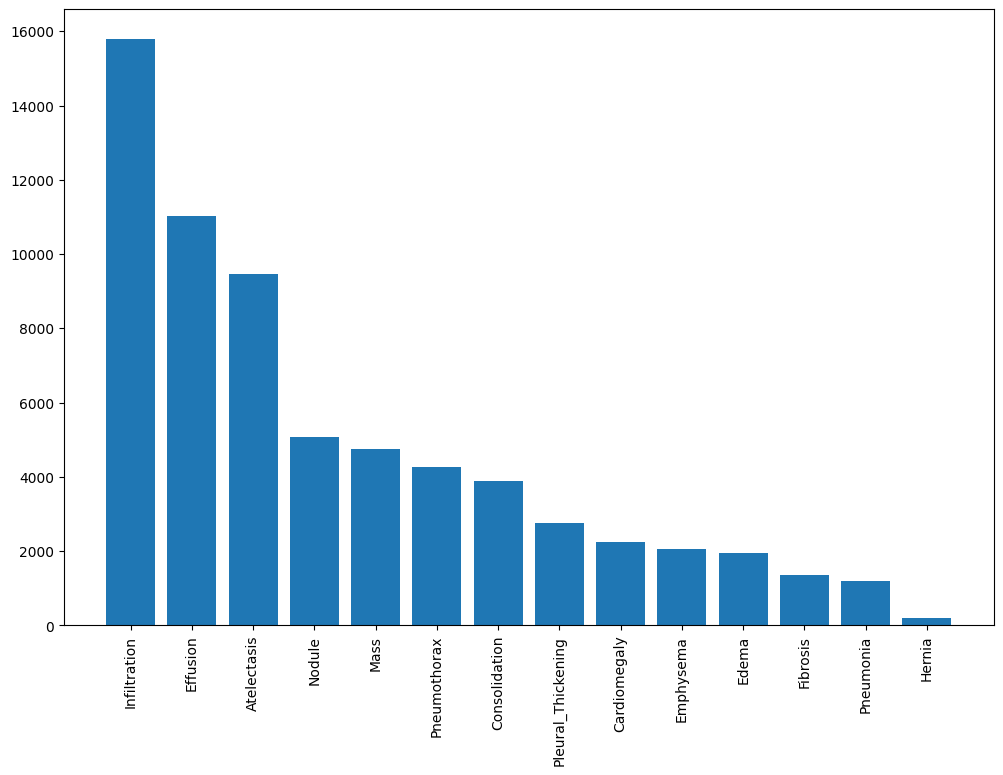

In [8]:
# Resample to create more balanced dataset with weighted sampling
xray_collected = xray_collected.with_columns(
    pl.col('Finding Labels').map_elements(
        lambda x: len(x.split('|')) if len(x) > 0 else 0,
        return_dtype=pl.Int32
    ).alias('num_findings')
)

# Calculate sample weights
sample_weights = xray_collected['num_findings'] + 0.04
# Normalize to create probabilities
sample_weights_normalized = sample_weights / sample_weights.sum()

# Resample using weights (approximate with sort and slice)
xray_collected = (
    xray_collected
    .with_columns(
        (pl.lit(np.random.random(len(xray_collected))) * -pl.col('num_findings')).alias('_sort_key')
    )
    .sort('_sort_key')
    .head(40000)
    .drop('_sort_key', 'num_findings')
)

# Re-analyze label distribution after resampling
label_counts_resampled = (
    xray_collected
    .select('Finding Labels')
    .with_columns(
        pl.col('Finding Labels').str.split('|').alias('labels_list')
    )
    .explode('labels_list')
    .filter(pl.col('labels_list') != '')
    .group_by('labels_list')
    .len()
    .sort('len', descending=True)
)

fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))
labels_resampled = label_counts_resampled['labels_list'].to_list()
counts_resampled = label_counts_resampled['len'].to_list()
ax1.bar(np.arange(len(counts_resampled)) + 0.5, counts_resampled)
ax1.set_xticks(np.arange(len(counts_resampled)) + 0.5)
_ = ax1.set_xticklabels(labels_resampled, rotation=90)

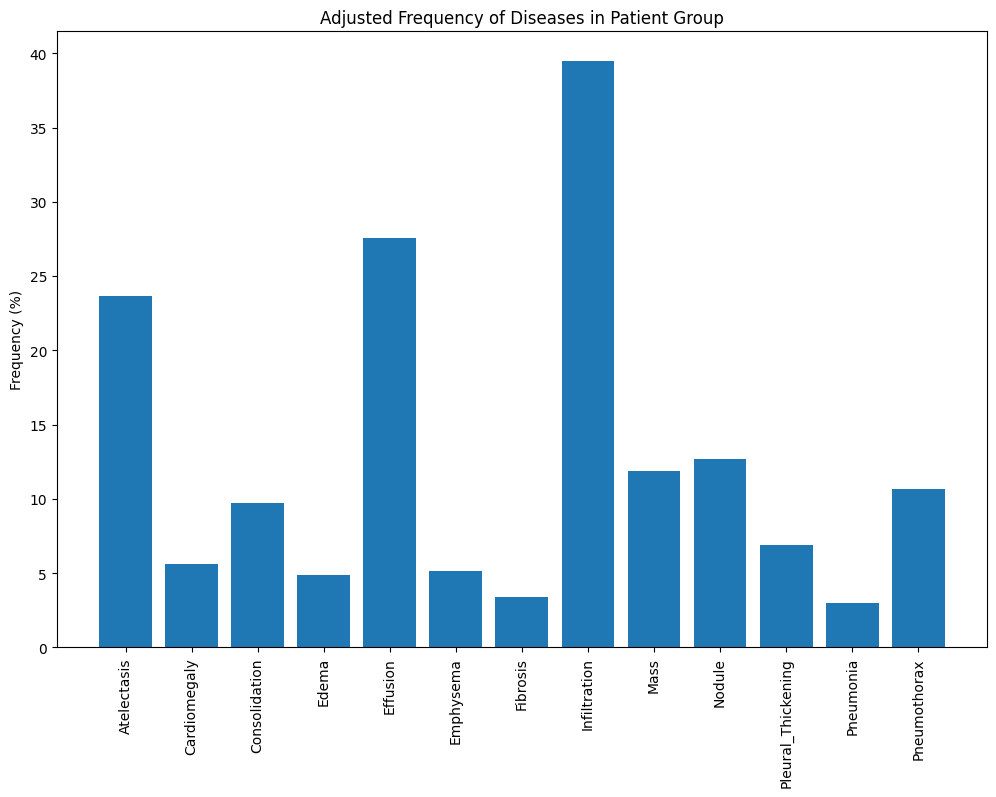

In [9]:
# Calculate adjusted frequency of diseases
label_frequencies = 100 * np.array([xray_collected[label].mean() for label in all_labels])
fig, ax1 = plt.subplots(1, 1, figsize=(12, 8))
ax1.bar(np.arange(len(label_frequencies)) + 0.5, label_frequencies)
ax1.set_xticks(np.arange(len(label_frequencies)) + 0.5)
ax1.set_xticklabels(all_labels, rotation=90)
ax1.set_title('Adjusted Frequency of Diseases in Patient Group')
_ = ax1.set_ylabel('Frequency (%)')

# Prepare Training Data
Here we split the data into training and validation sets and create a single vector (disease_vec) with the 0/1 outputs for the disease status (what the model will try and predict)

In [10]:
# Create disease vector for each sample
xray_collected = xray_collected.with_columns(
    pl.concat_list(all_labels).map_elements(
        lambda x: np.array(x, dtype=np.float32),
        return_dtype=pl.Object
    ).alias('disease_vec')
)

In [11]:
from sklearn.model_selection import train_test_split

# Convert to needed format for train_test_split
xray_py = xray_collected.to_pandas()
train_df, valid_df = train_test_split(
    xray_py,
    test_size=0.25,
    random_state=2018,
    stratify=xray_py['Finding Labels'].eq('No Finding'),
)

train_df = train_df.copy()
valid_df = valid_df.copy()
train_df['sample_weight'] = np.where(
    train_df['Finding Labels'].eq('No Finding'),
    0.35,
    1.0,
)

# Convert back to Polars
train_df = pl.from_pandas(train_df)
valid_df = pl.from_pandas(valid_df)

print(f'train: {len(train_df)}, validation: {len(valid_df)}')

train: 30000, validation: 10000


# Create Data Generators
Here we make the data generators for loading and randomly transforming images

In [12]:
from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
IMG_SIZE = (128, 128)

# Separate augmentation for training and deterministic preprocessing for validation/test.
train_idg = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    vertical_flip=False,
    height_shift_range=0.05,
    width_shift_range=0.1,
    rotation_range=5,
    shear_range=0.1,
    fill_mode='reflect',
    zoom_range=0.15,
)

eval_idg = ImageDataGenerator(
    preprocessing_function=preprocess_input,
)

In [13]:
def flow_from_dataframe(img_data_gen, in_df, path_col, y_col, weight_col=None, **dflow_args):
    if hasattr(in_df, 'to_pandas'):
        in_df = in_df.to_pandas()

    print('Building generator from dataframe...')
    df_gen = img_data_gen.flow_from_dataframe(
        dataframe=in_df,
        x_col=path_col,
        y_col=y_col,
        weight_col=weight_col,
        class_mode='raw',
        validate_filenames=False,
        **dflow_args,
    )
    if weight_col is not None:
        print('Using sample weights from column: {}'.format(weight_col))
    print('Generator ready: {} images'.format(len(in_df)))
    return df_gen

In [14]:
train_gen = flow_from_dataframe(
    train_idg,
    train_df,
    path_col='path',
    y_col=all_labels,
    weight_col='sample_weight',
    target_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    seed=2018,
 )

valid_gen = flow_from_dataframe(
    eval_idg,
    valid_df,
    path_col='path',
    y_col=all_labels,
    target_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    seed=2018,
 )

valid_eval_gen = flow_from_dataframe(
    eval_idg,
    valid_df,
    path_col='path',
    y_col=all_labels,
    target_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    seed=2018,
 )

test_Y = np.concatenate(
    [valid_eval_gen[index][1] for index in range(len(valid_eval_gen))],
    axis=0,
)

Building generator from dataframe...
Found 30000 non-validated image filenames.
Using sample weights from column: sample_weight
Generator ready: 30000 images
Building generator from dataframe...
Found 10000 non-validated image filenames.
Generator ready: 10000 images
Building generator from dataframe...
Found 10000 non-validated image filenames.
Generator ready: 10000 images


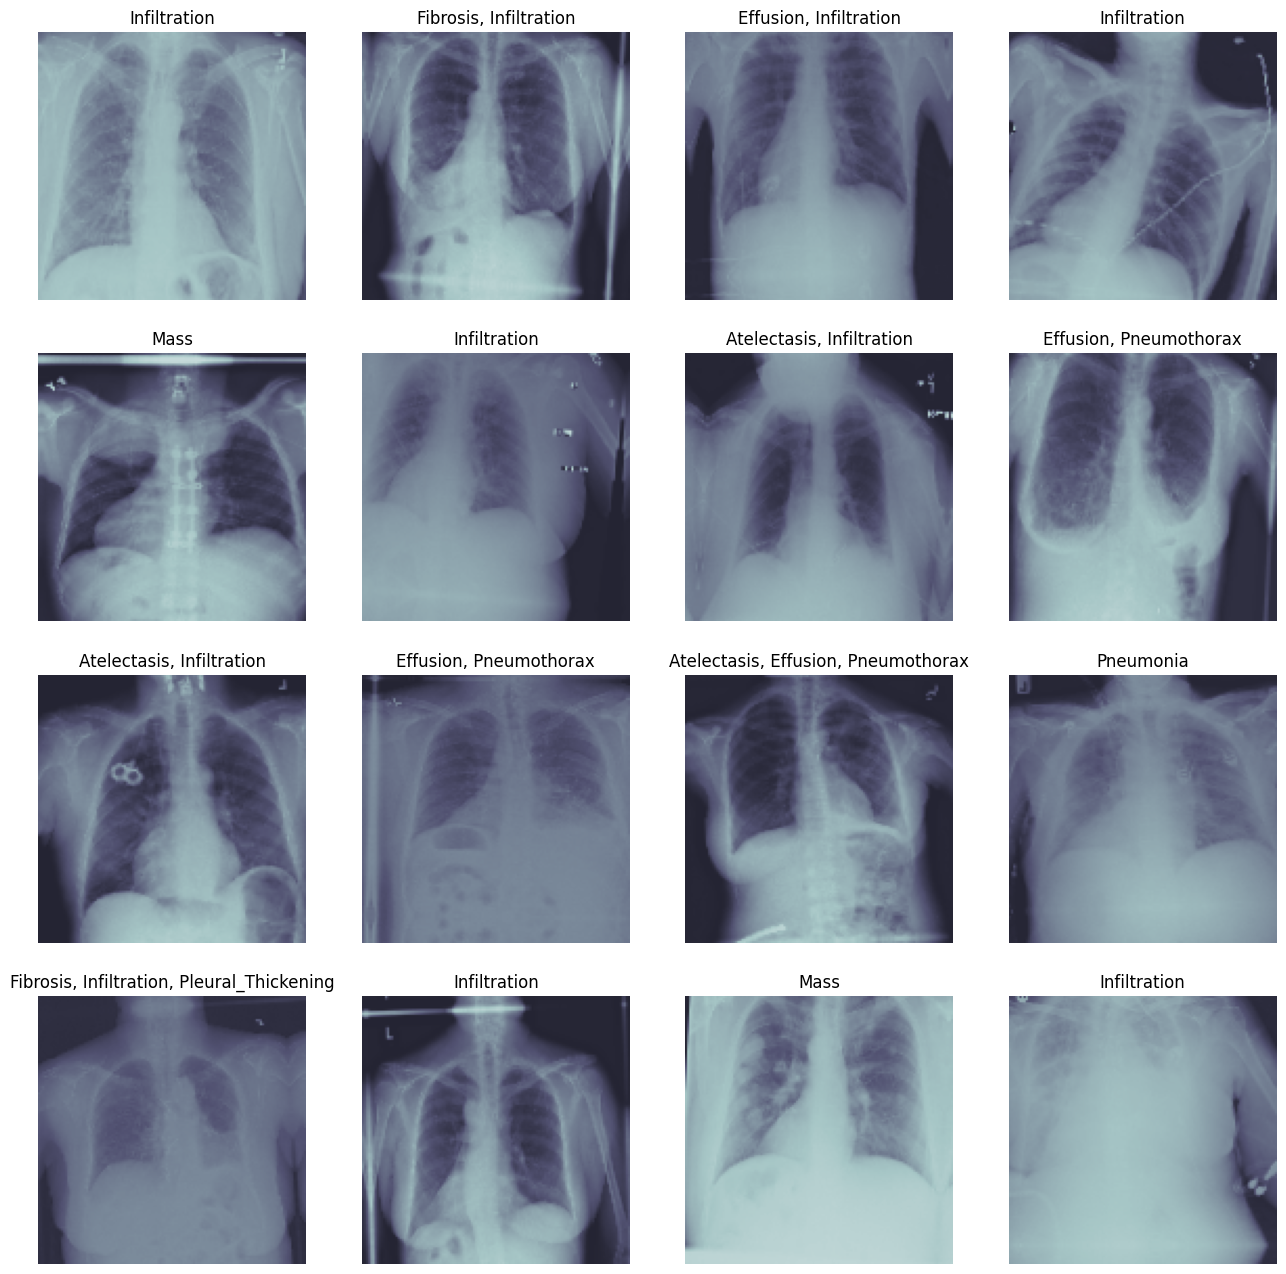

In [15]:
t_x, t_y, _ = next(train_gen)
fig, m_axs = plt.subplots(4, 4, figsize = (16, 16))
for (c_x, c_y, c_ax) in zip(t_x, t_y, m_axs.flatten()):
    c_ax.imshow(c_x[:,:,0], cmap = 'bone', vmin = -1.5, vmax = 1.5)
    c_ax.set_title(', '.join([n_class for n_class, n_score in zip(all_labels, c_y) 
                             if n_score>0.5]))
    c_ax.axis('off')

# Create a simple model
Here we make a simple model to train using MobileNet as a base and then adding a GAP layer (Flatten could also be added), dropout, and a fully-connected layer to calculate specific features

In [16]:
from keras.applications.mobilenet import MobileNet
from keras.layers import GlobalAveragePooling2D, Dense, Dropout
from keras.metrics import AUC
from keras.models import Sequential
from keras.optimizers import Adam

# Test transfer learning with explicit ImageNet weights.
use_imagenet_weights = True
backbone_weights = 'imagenet' if use_imagenet_weights else None

base_mobilenet_model = MobileNet(
    input_shape=t_x.shape[1:],
    include_top=False,
    weights=backbone_weights,
)

# Critical: if the backbone is random (weights=None), it must be trainable.
freeze_backbone = use_imagenet_weights
for layer in base_mobilenet_model.layers:
    layer.trainable = not freeze_backbone

multi_disease_model = Sequential()
multi_disease_model.add(base_mobilenet_model)
multi_disease_model.add(GlobalAveragePooling2D())
multi_disease_model.add(Dropout(0.5))
multi_disease_model.add(Dense(512, activation='relu'))
multi_disease_model.add(Dropout(0.5))
multi_disease_model.add(Dense(len(all_labels), activation='sigmoid', dtype='float32'))
multi_disease_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['binary_accuracy', 'mae', AUC(name='auc', multi_label=True)],
)
print(f'Using ImageNet weights: {use_imagenet_weights} | backbone_frozen={freeze_backbone}')
multi_disease_model.summary()

Using ImageNet weights: True | backbone_frozen=True


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_128 (Functional) │ (None, 4, 4, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         6,669 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,760,333 (14.34 MB)

 Trainable params: 531,469 (2.03 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [17]:
from keras.callbacks import ModelCheckpoint, EarlyStopping
from pathlib import Path
import os

# Use repository-managed weights path when available
candidate_weight_paths = [
    Path('case') / 'xray_class.weights.h5',
    Path('xray_class.weights.h5'),
]
weight_path = next((str(p) for p in candidate_weight_paths if p.exists()), str(candidate_weight_paths[0]))

checkpoint = ModelCheckpoint(
    weight_path,
    monitor='val_auc',
    verbose=1,
    save_best_only=True,
    mode='max',
    save_weights_only=True,
)

early = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=4,
    restore_best_weights=True,
)
callbacks_list = [checkpoint, early]

# Enable training by default so the notebook validates the real pipeline, not stale weights.
RUN_TRAINING = os.environ.get('EU_AI_ACT_RUN_TRAINING', '1') != '0'
TRAIN_STEPS_PER_EPOCH = min(len(train_gen), int(os.environ.get('EU_AI_ACT_TRAIN_STEPS_PER_EPOCH', '40')))
FINE_TUNE_STEPS_PER_EPOCH = min(len(train_gen), int(os.environ.get('EU_AI_ACT_FINE_TUNE_STEPS_PER_EPOCH', '40')))
VALIDATION_STEPS = min(len(valid_gen), int(os.environ.get('EU_AI_ACT_VALIDATION_STEPS', '20')))

print(
    f'RUN_TRAINING={RUN_TRAINING} | weight_path={weight_path} | '
    f'train_steps={TRAIN_STEPS_PER_EPOCH} | finetune_steps={FINE_TUNE_STEPS_PER_EPOCH} | val_steps={VALIDATION_STEPS}'
)

RUN_TRAINING=True | weight_path=xray_class.weights.h5 | train_steps=40 | finetune_steps=40 | val_steps=20


# First Round
Here we do a first round of training to get a few initial low hanging fruit results

In [18]:
if RUN_TRAINING:
    history = multi_disease_model.fit(
        train_gen,
        steps_per_epoch=TRAIN_STEPS_PER_EPOCH,
        validation_data=valid_gen,
        validation_steps=VALIDATION_STEPS,
        epochs=3,
        callbacks=callbacks_list,
    )
else:
    print('First training round skipped (RUN_TRAINING=False).')

Epoch 1/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 636ms/step - auc: 0.5013 - binary_accuracy: 0.7042 - loss: 0.9835 - mae: 0.3085
Epoch 1: val_auc improved from None to 0.53191, saving model to xray_class.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - auc: 0.4961 - binary_accuracy: 0.7737 - loss: 0.8348 - mae: 0.2403 - val_auc: 0.5319 - val_binary_accuracy: 0.8713 - val_loss: 0.5396 - val_mae: 0.1376
Epoch 2/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 635ms/step - auc: 0.5186 - binary_accuracy: 0.8197 - loss: 0.7338 - mae: 0.1963
Epoch 2: val_auc improved from 0.53191 to 0.55018, saving model to xray_class.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - auc: 0.5187 - binary_accuracy: 0.8188 - loss: 0.7127 - mae: 0.1974 - val_auc: 0.5502 - val_binary_accuracy: 0.8714 - val_loss: 0.4941 - val_mae: 0.1393
Epoch 3/3
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - auc: 0.4992 - binary_accuracy: 0.8143 - loss: 0.7371 - mae: 0.2009
Epoch 3: val_auc improved from 0.55018 to 0.56544, saving model to xray_class.w

# Check Output
Here we see how many positive examples we have of each category

In [19]:
for c_label, s_count in zip(all_labels, 100*np.mean(test_Y,0)):
    print('%s: %2.2f%%' % (c_label, s_count))

Atelectasis: 23.80%
Cardiomegaly: 5.85%
Consolidation: 10.01%
Edema: 5.08%
Effusion: 28.05%
Emphysema: 5.39%
Fibrosis: 3.49%
Infiltration: 39.21%
Mass: 11.85%
Nodule: 12.85%
Pleural_Thickening: 6.67%
Pneumonia: 2.86%
Pneumothorax: 10.44%


In [20]:
if hasattr(valid_eval_gen, 'reset'):
    valid_eval_gen.reset()
pred_Y = multi_disease_model.predict(valid_eval_gen, steps=len(valid_eval_gen), verbose=True)

79/79 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step


# ROC Curves
While a very oversimplified metric, we can show the ROC curve for each metric

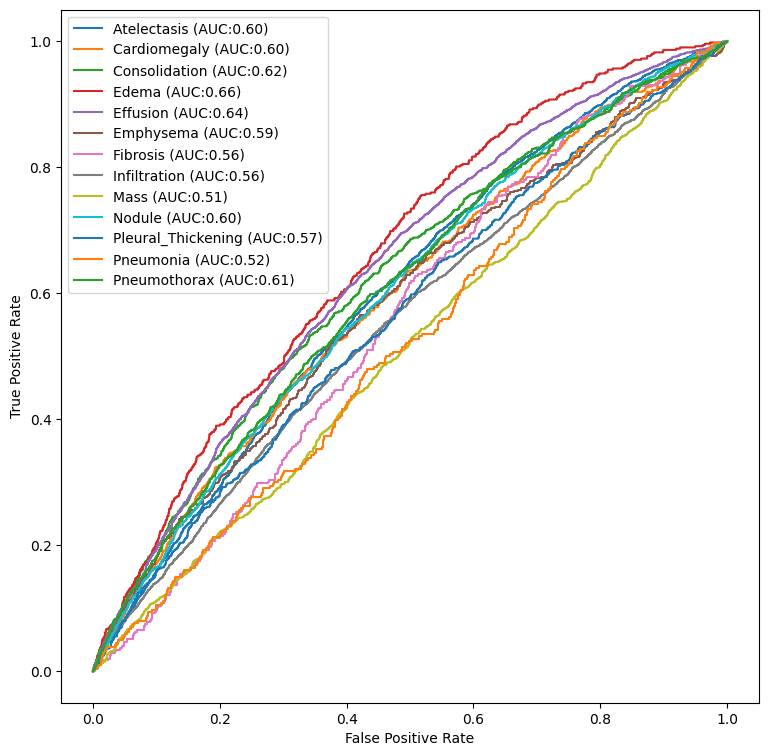

In [21]:
from sklearn.metrics import roc_curve, auc
fig, c_ax = plt.subplots(1,1, figsize = (9, 9))
for (idx, c_label) in enumerate(all_labels):
    fpr, tpr, thresholds = roc_curve(test_Y[:,idx].astype(int), pred_Y[:,idx])
    c_ax.plot(fpr, tpr, label = '%s (AUC:%0.2f)'  % (c_label, auc(fpr, tpr)))
c_ax.legend()
c_ax.set_xlabel('False Positive Rate')
c_ax.set_ylabel('True Positive Rate')
fig.savefig('barely_trained_net.png')

# Continued Training
Now we do a much longer training process to see how the results improve

In [22]:
if RUN_TRAINING:
    for layer in base_mobilenet_model.layers[-20:]:
        layer.trainable = True
    multi_disease_model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss='binary_crossentropy',
        metrics=['binary_accuracy', 'mae', AUC(name='auc', multi_label=True)],
    )
    history = multi_disease_model.fit(
        train_gen,
        steps_per_epoch=FINE_TUNE_STEPS_PER_EPOCH,
        validation_data=valid_gen,
        validation_steps=VALIDATION_STEPS,
        epochs=5,
        callbacks=callbacks_list,
    )
else:
    print('Continued training skipped (RUN_TRAINING=False).')

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - auc: 0.5147 - binary_accuracy: 0.8046 - loss: 0.6569 - mae: 0.2173
Epoch 1: val_auc improved from 0.56544 to 0.56584, saving model to xray_class.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - auc: 0.5168 - binary_accuracy: 0.8066 - loss: 0.6534 - mae: 0.2148 - val_auc: 0.5658 - val_binary_accuracy: 0.8716 - val_loss: 0.4615 - val_mae: 0.1419
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 653ms/step - auc: 0.5075 - binary_accuracy: 0.8101 - loss: 0.6480 - mae: 0.2108
Epoch 2: val_auc improved from 0.56584 to 0.57017, saving model to xray_class.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - auc: 0.5164 - binary_accuracy: 0.8133 - loss: 0.6351 - mae: 0.2079 - val_auc: 0.5702 - val_binary_accuracy: 0.8714 - val_loss: 0.4523 - val_mae: 0.1431
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - auc: 0.5314 - binary_accuracy: 0.8133 - loss: 0.6441 - mae: 0.2074
Epoch 3: val_auc improved from 0.57017 to 0.57171, saving model to xray_clas

In [23]:
# Load best available weights for stable evaluation/integration
from pathlib import Path

if Path(weight_path).exists():
    try:
        multi_disease_model.load_weights(weight_path)
        print(f'Loaded weights from {weight_path}')
    except ValueError as exc:
        print('Could not load saved weights due to architecture mismatch.')
        print(f'Reason: {exc}')
        print('Continuing with current model weights.')
else:
    print(f'No weights found at {weight_path}. Model remains with current parameters.')

Loaded weights from xray_class.weights.h5


In [24]:
if hasattr(valid_eval_gen, 'reset'):
    valid_eval_gen.reset()
pred_Y = multi_disease_model.predict(valid_eval_gen, steps=len(valid_eval_gen), verbose=True)

79/79 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step


In [25]:
# look at how often the algorithm predicts certain diagnoses 
for c_label, p_count, t_count in zip(all_labels, 
                                     100*np.mean(pred_Y,0), 
                                     100*np.mean(test_Y,0)):
    print('%s: Dx: %2.2f%%, PDx: %2.2f%%' % (c_label, t_count, p_count))

Atelectasis: Dx: 23.80%, PDx: 9.83%
Cardiomegaly: Dx: 5.85%, PDx: 0.64%
Consolidation: Dx: 10.01%, PDx: 2.56%
Edema: Dx: 5.08%, PDx: 0.87%
Effusion: Dx: 28.05%, PDx: 15.16%
Emphysema: Dx: 5.39%, PDx: 0.48%
Fibrosis: Dx: 3.49%, PDx: 0.35%
Infiltration: Dx: 39.21%, PDx: 29.17%
Mass: Dx: 11.85%, PDx: 2.61%
Nodule: Dx: 12.85%, PDx: 2.19%
Pleural_Thickening: Dx: 6.67%, PDx: 1.04%
Pneumonia: Dx: 2.86%, PDx: 0.39%
Pneumothorax: Dx: 10.44%, PDx: 1.58%


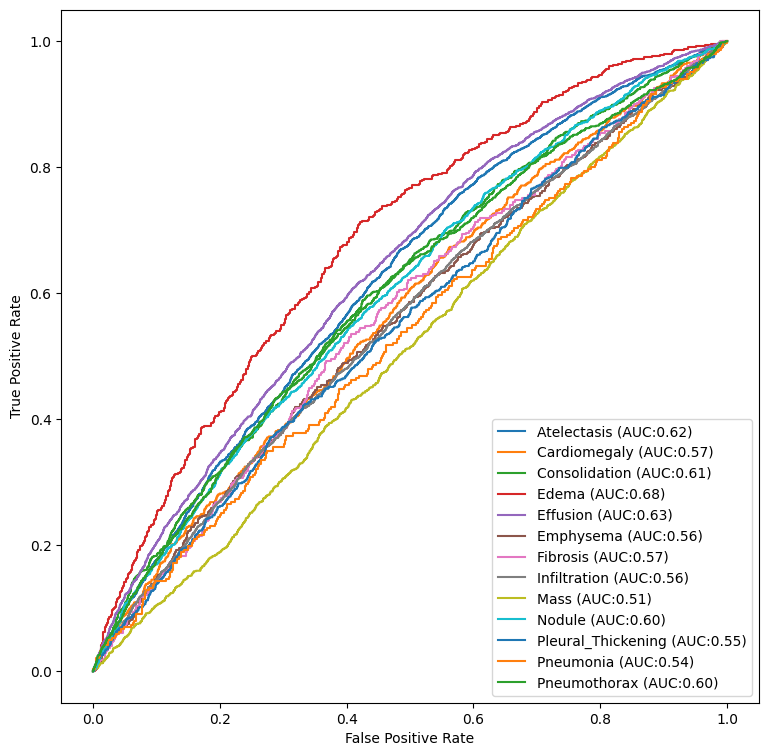

In [26]:
from sklearn.metrics import roc_curve, auc
fig, c_ax = plt.subplots(1,1, figsize = (9, 9))
for (idx, c_label) in enumerate(all_labels):
    fpr, tpr, thresholds = roc_curve(test_Y[:,idx].astype(int), pred_Y[:,idx])
    c_ax.plot(fpr, tpr, label = '%s (AUC:%0.2f)'  % (c_label, auc(fpr, tpr)))
c_ax.legend()
c_ax.set_xlabel('False Positive Rate')
c_ax.set_ylabel('True Positive Rate')
fig.savefig('trained_net.png')

# Show a few images and associated predictions

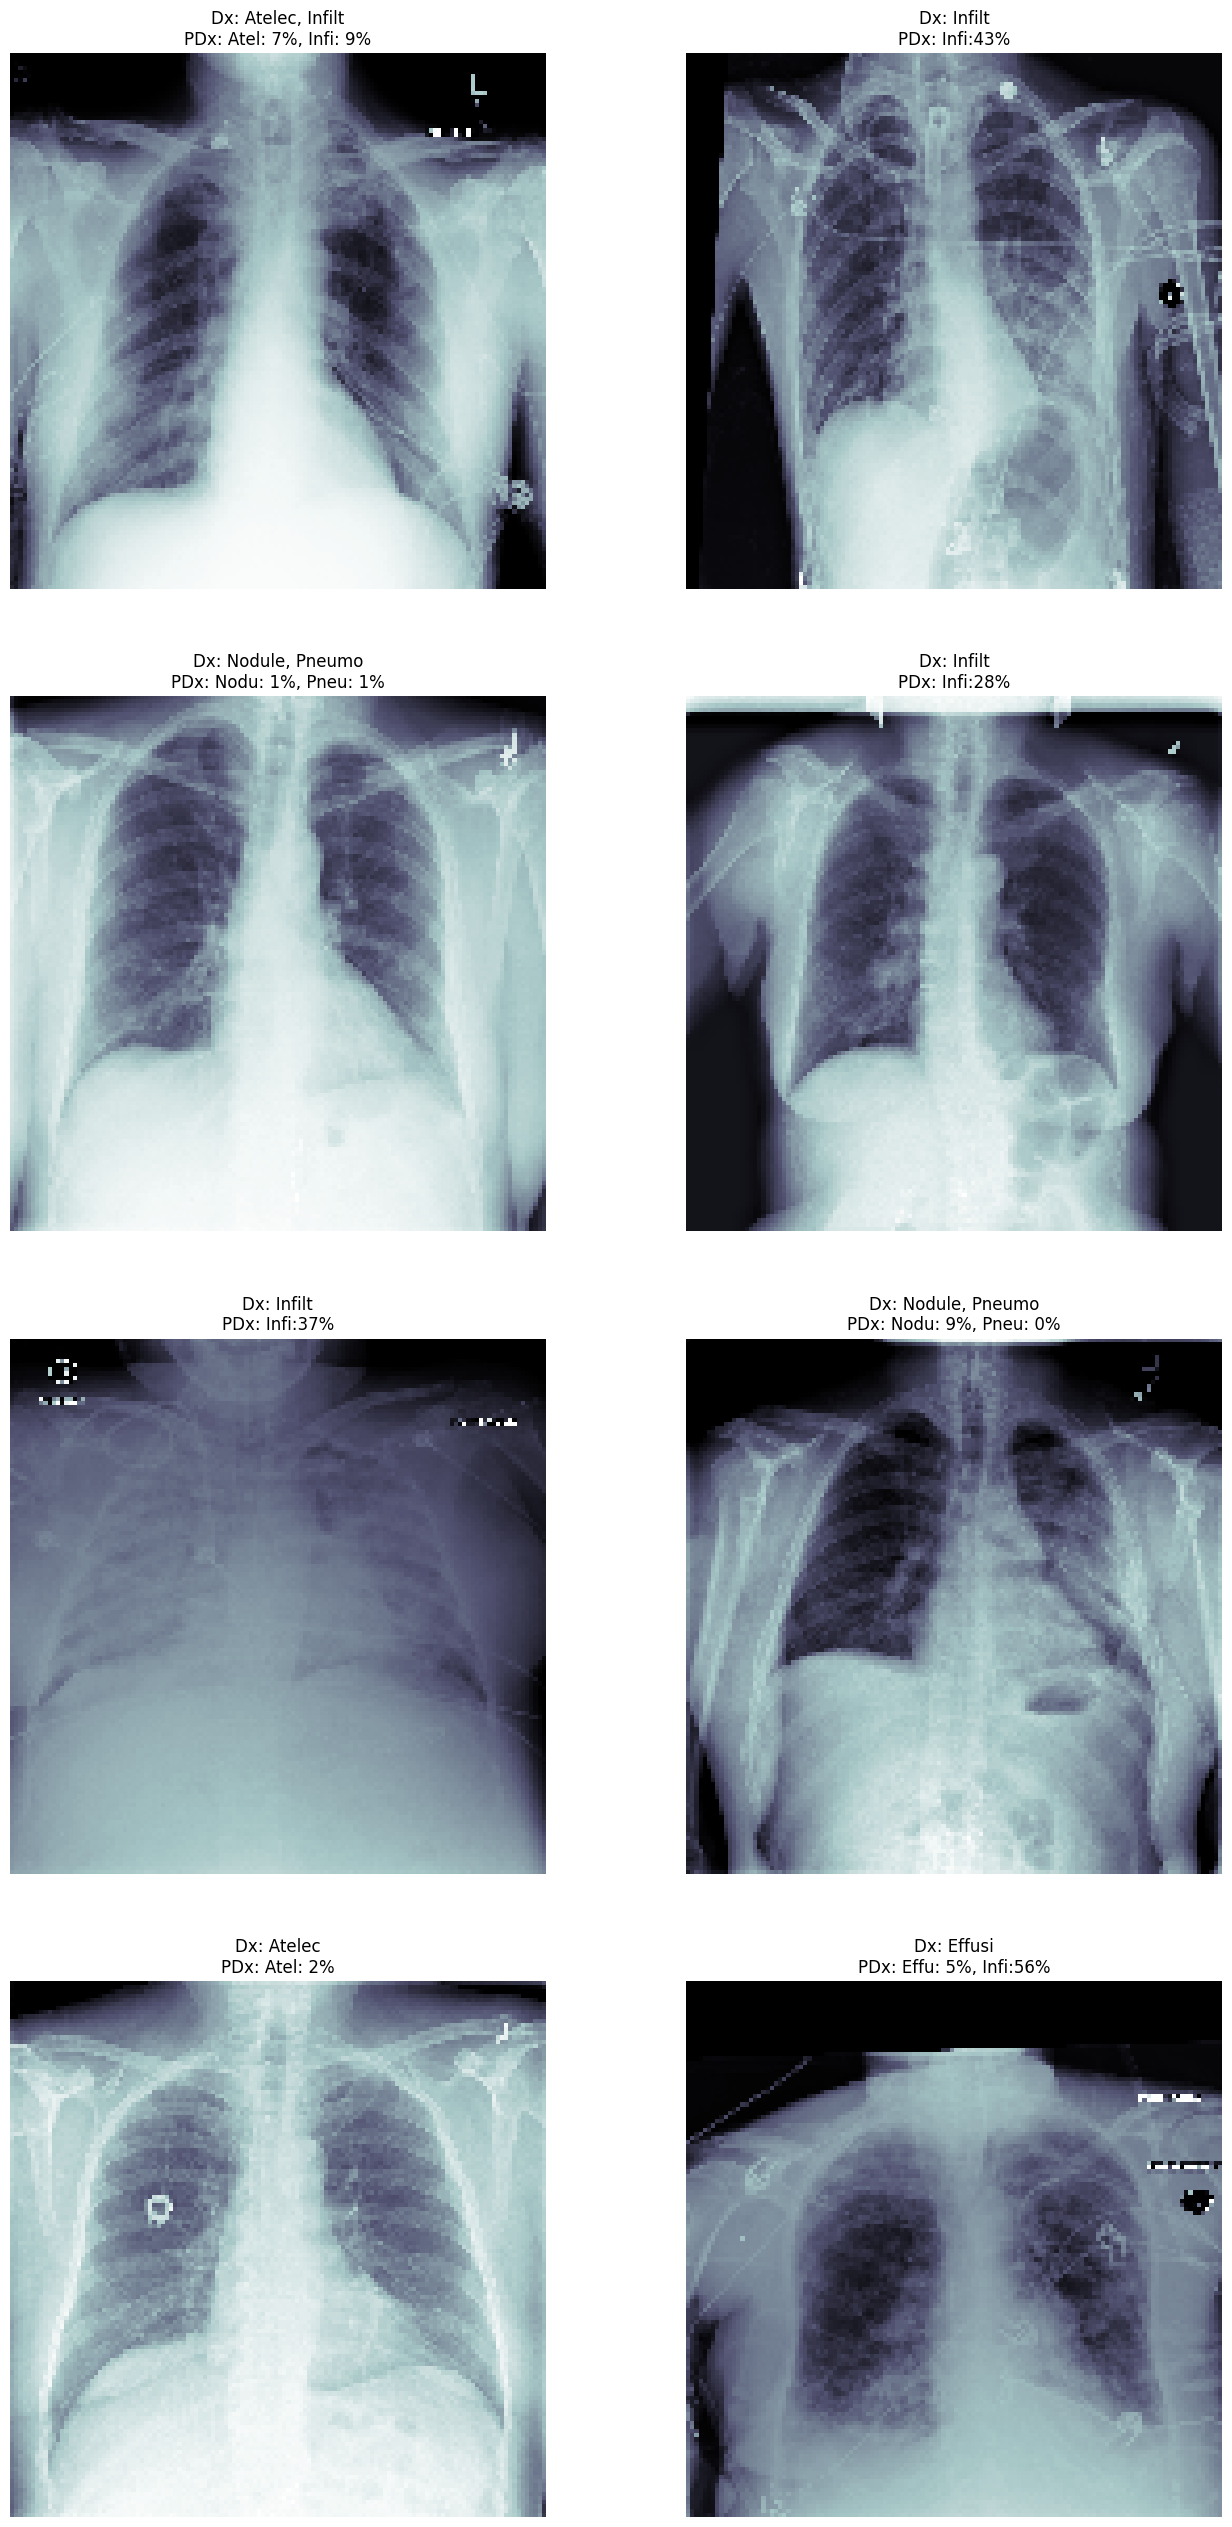

In [27]:
if 'test_X' not in globals():
    if hasattr(valid_eval_gen, 'reset'):
        valid_eval_gen.reset()
    test_X = np.concatenate(
        [valid_eval_gen[i][0] for i in range(len(valid_eval_gen))],
        axis=0,
    )
    if hasattr(valid_eval_gen, 'reset'):
        valid_eval_gen.reset()

sickest_idx = np.argsort(np.sum(test_Y, 1) < 1)
fig, m_axs = plt.subplots(4, 2, figsize=(16, 32))
for (idx, c_ax) in zip(sickest_idx, m_axs.flatten()):
    c_ax.imshow(test_X[idx, :, :, 0], cmap='bone')
    stat_str = [
        n_class[:6] for n_class, n_score in zip(all_labels, test_Y[idx])
        if n_score > 0.5
    ]
    pred_str = [
        '%s:%2.0f%%' % (n_class[:4], p_score * 100)
        for n_class, n_score, p_score in zip(all_labels, test_Y[idx], pred_Y[idx])
        if (n_score > 0.5) or (p_score > 0.5)
    ]
    c_ax.set_title('Dx: ' + ', '.join(stat_str) + '\nPDx: ' + ', '.join(pred_str))
    c_ax.axis('off')
fig.savefig('trained_img_predictions.png')

# Real Integration Test with `eu_ai_act` Package
This test connects the trained Keras model and a real NIH validation subset to the package pipeline (`adapters` + `evaluator` + `reporting`).

In [28]:
from pathlib import Path
import sys

# Ensure the package source is importable from notebook context
project_root = Path.cwd().resolve()
if not (project_root / 'src' / 'eu_ai_act').exists():
    for parent in [project_root, *project_root.parents]:
        if (parent / 'src' / 'eu_ai_act').exists():
            project_root = parent
            break

src_path = str(project_root / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from eu_ai_act.adapters import InMemoryDatasetAdapter, KerasModelAdapter
from eu_ai_act.evaluation import ComplianceEvaluator
from eu_ai_act.reporting import export_assessment_json, export_assessment_markdown, export_assessment_pdf

print(f'Using project root: {project_root}')

Using project root: /Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Desarrollos/EU_AI_ACT


In [29]:
def age_bucket(value):
    try:
        age = int(value)
    except Exception:
        return 'unknown'
    if age < 30:
        return 'young'
    if age < 60:
        return 'adult'
    return 'senior'

# Use a real subset from validation tensors generated above
subset_size = min(512, len(test_X))
features_subset = [test_X[i] for i in range(subset_size)]
features_np = np.array(features_subset)

# Score all outputs and pick a stable target label for integration checks
all_scores = multi_disease_model.predict(features_np, verbose=0)
std_per_label = all_scores.std(axis=0)

preferred_label = 'Infiltration'
preferred_idx = all_labels.index(preferred_label) if preferred_label in all_labels else 0

if float(std_per_label[preferred_idx]) < 1e-4:
    target_idx = int(np.argmax(std_per_label))
else:
    target_idx = preferred_idx

target_label = all_labels[target_idx]
labels_subset = [float(test_Y[i][target_idx]) for i in range(subset_size)]

class SingleOutputWrapper:
    def __init__(self, base_model, output_index):
        self.base_model = base_model
        self.output_index = output_index
        self.__class__.__name__ = 'SingleOutputWrapper'

    def predict(self, x, verbose=0):
        y = self.base_model.predict(x, verbose=verbose)
        return y[:, self.output_index:self.output_index + 1]

single_target_model = SingleOutputWrapper(multi_disease_model, target_idx)
pred_scores = single_target_model.predict(features_np, verbose=0).reshape(-1)

# Calibrate threshold to match observed prevalence on this subset
true_positive_rate = float(np.mean(labels_subset))
quantile = max(0.0, min(1.0, 1.0 - true_positive_rate))
prediction_threshold = float(np.quantile(pred_scores, quantile))

valid_subset_df = valid_df.head(subset_size)
valid_rows = valid_subset_df.to_dicts()
metadata_subset = [
    {
        'gender': str(row.get('Patient Gender', 'unknown')),
        'age_group': age_bucket(row.get('Patient Age')),
        'view_position': str(row.get('View Position', 'unknown')),
    }
    for row in valid_rows
]

dataset_adapter = InMemoryDatasetAdapter(
    features=features_subset,
    labels=labels_subset,
    metadata=metadata_subset,
)

model_adapter = KerasModelAdapter(model=single_target_model, model_name=f'nih-mobilenet-{target_label.lower()}')

evaluator = ComplianceEvaluator(
    batch_size=32,
    prediction_threshold=prediction_threshold,
    stress_domain='nih_chest_xrays',
)

assessment, summary = evaluator.evaluate(model_adapter, dataset_adapter)

output_dir = project_root / 'outputs' / 'real_integration_test'
output_dir.mkdir(parents=True, exist_ok=True)

json_report = export_assessment_json(assessment, output_dir / 'assessment.json')
md_report = export_assessment_markdown(assessment, output_dir / 'assessment.md')
pdf_report = export_assessment_pdf(assessment, output_dir / 'assessment.pdf')

pred_positive_rate = float((pred_scores >= prediction_threshold).mean())

print('Integration test completed')
print(f'Preferred label: {preferred_label} | Selected label: {target_label} (index={target_idx})')
print(f'Label score std: {float(std_per_label[target_idx]):.6f}')
print(f'Samples: {summary.sample_count}, Batches: {summary.batch_count}')
print(f'Stress domain: {summary.stress_domain}')
print(f'Calibrated threshold: {prediction_threshold:.4f}')
print(f'Risk records: {assessment.risk_register.to_dict()["total_records"]}')
print(f'Positive rate (true/pred): {true_positive_rate:.3f} / {pred_positive_rate:.3f}')
print('Reports:')
print(f'  - {json_report}')
print(f'  - {md_report}')
print(f'  - {pdf_report}')

Integration test completed
Preferred label: Infiltration | Selected label: Infiltration (index=7)
Label score std: 0.200743
Samples: 512, Batches: 16
Stress domain: nih_chest_xrays
Calibrated threshold: 0.3112
Risk records: 4
Positive rate (true/pred): 0.391 / 0.391
Reports:
  - /Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Desarrollos/EU_AI_ACT/outputs/real_integration_test/assessment.json
  - /Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Desarrollos/EU_AI_ACT/outputs/real_integration_test/assessment.md
  - /Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Desarrollos/EU_AI_ACT/outputs/real_integration_test/assessment.pdf


In [30]:

pdf_report = export_assessment_pdf(assessment, output_dir / 'assessment.pdf')


In [31]:
# Diagnostic check: score distribution for selected target output
print('Score min/max/std:', float(pred_scores.min()), float(pred_scores.max()), float(pred_scores.std()))
print('Approx unique scores (rounded 4d):', len(set(np.round(pred_scores, 4))))

Score min/max/std: 0.008626000955700874 0.9587650895118713 0.20074328780174255
Approx unique scores (rounded 4d): 486
